In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

Fitted RF_SBP
Fitted RF_DBP
Finished calculating permutation importance for SBP
Finished importance list for SBP
Finished calculating permutation importance for DBP
Finished importance list for DBP


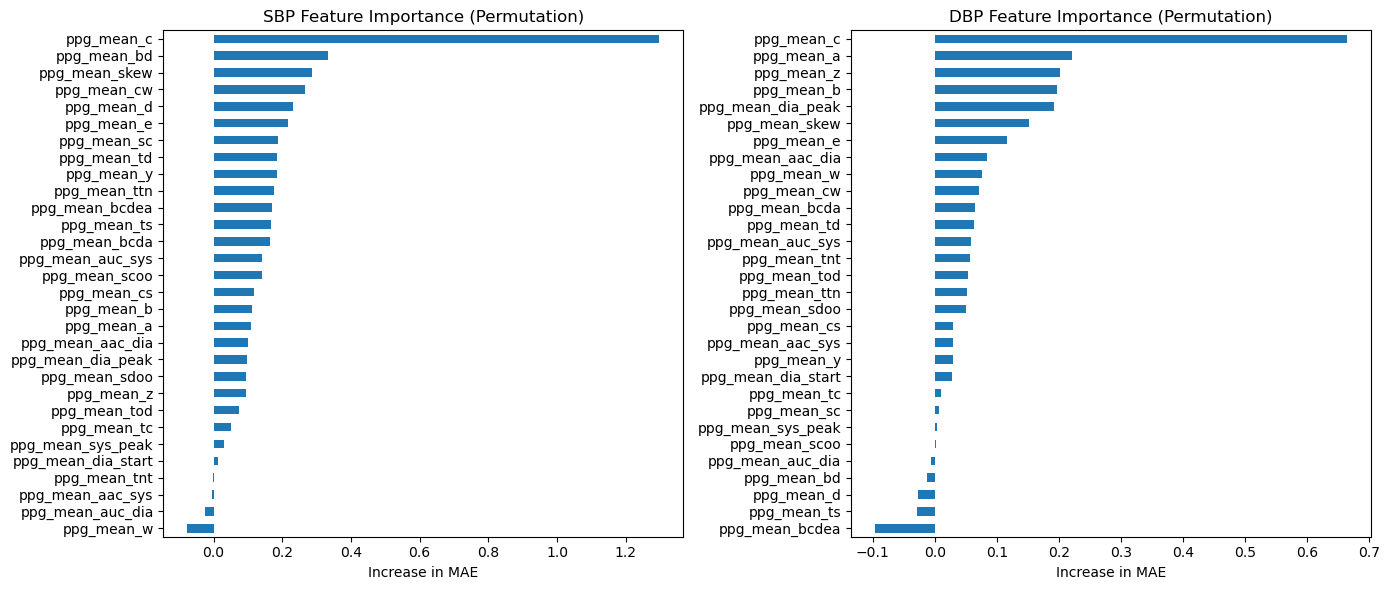

In [ ]:
df = pd.read_csv('ABP_PPG_features.csv')

y_SBP = df['SBP']
y_DBP = df['DBP']

exclude_cols = [
    "data ID", "struct", "SBP", "DBP",
    "ppg_mean_mean_sbp", "ppg_mean_mean_dbp",
    "ppg_mean_sbp_class", "ppg_mean_dbp_class"
]

feature_cols = [c for c in df.columns if c not in exclude_cols]

X = df[feature_cols]


'''
X_train: Contains 80% of the dataset rows/samples used as input to train model
y_SBP_train: Contains 80% of the same dataset rows/samples from X_train used as target/output of the trained model
X_val: Contains 20% of the dataset rows/samples used as input to the trained model to predict
y_SBP_val: Contains 20% of the same dataset rows/samples used in X_val used as the true value the trained model needs to predict
'''
X_train, X_val, y_SBP_train, y_SBP_val = train_test_split(
    X, y_SBP, test_size=0.2, random_state=42
)

_, _, y_DBP_train, y_DBP_val = train_test_split(
    X, y_DBP, test_size=0.2, random_state=42
)


# RF for SBP (with bootstrapping or no?)
RF_SBP = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


# RF for DBP (with bootstrapping or no?)
RF_DBP = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)


RF_SBP.fit(X_train,y_SBP_train)
print('Fitted RF_SBP')
RF_DBP.fit(X_train,y_DBP_train)
print('Fitted RF_DBP')

'''
We simply train the models using the original sequence of features, 
then for each feature we permute it n_repeat times and for each repeat 
i.e. permutation we see if the model that we trained on the original sequence 
of samples now predicts worse than it predicted on the original test set.
So we still use the same test set but we permute the values in there.
We then take the mean absolute error of all these repeat runs and this is our metric to 
compare feature importance then. So the higher increase in error the more important the feature
'''

result_SBP = permutation_importance(
    RF_SBP,
    X_val,
    y_SBP_val,
    scoring='neg_mean_absolute_error',
    n_repeats=50,
    n_jobs=-1,
    random_state=42
)
print("Finished calculating permutation importance for SBP")

SBP_importance = pd.Series(
    result_SBP.importances_mean,
    index=feature_cols
).sort_values(ascending=False)
print("Finished importance list for SBP")


result_DBP = permutation_importance(
    RF_DBP,
    X_val,
    y_DBP_val,
    scoring='neg_mean_absolute_error',
    n_repeats=50,
    n_jobs=-1,
    random_state=42
)
print("Finished calculating permutation importance for DBP")

DBP_importance = pd.Series(
    result_DBP.importances_mean,
    index=feature_cols
).sort_values(ascending=False)
print("Finished importance list for DBP")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

SBP_importance.sort_values().plot.barh(ax=ax[0],color="skyblue")
ax[0].set_title("SBP Feature Importance (Permutation)")
ax[0].set_xlabel("Increase in MAE")

DBP_importance.sort_values().plot.barh(ax=ax[1],color="lightgreen")
ax[1].set_title("DBP Feature Importance (Permutation)")
ax[1].set_xlabel("Increase in MAE")

plt.tight_layout()
plt.savefig("feature_importancePermutationImp.png", dpi=300)
plt.show()


